# Chapter 46: Market Efficiency, Behavioral Finance, and Limits to Arbitrage

This notebook reruns four worked examples from the chapter: a report moving a share to its new benchmark price, a short squeezed by noise traders, a momentum long-short portfolio, and an arbitrage fund forced to sell by redemptions. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def net_abnormal(gross, costs):
    """efficient-market-hypothesis: net abnormal return = gross minus each implementation cost (percent units).

    Book: 0.60 - 0.30 - 0.25 - 0.15 = -0.10 percent.
    """
    return float(gross) - sum(float(c) for c in costs)


def short_mark(size, p0, p1, capital):
    """noise-trader-risk: marked P/L on a short of `size` claims sold at p0 and marked at p1.

    Returns {"pnl": size(p0 - p1), "loss": max(0, -pnl), "forced": loss > capital}.
    Book: 118 - 95 = 23, 118 - 165 = -47 (exceeds 45 of capital); half a share loses 23.50.
    """
    pnl = float(size) * (float(p0) - float(p1))
    loss = max(0.0, -pnl)
    return {"pnl": pnl, "loss": loss, "forced": loss > float(capital)}


def long_short(leg, r_long, r_short, cost=0.0):
    """momentum-effect: long-short profit on equal legs; returns as fractions.

    Book: 400,000(0.08) = 32,000; short loses 400,000(0.02) = 8,000; MOM = 6 percent, net of 4 percent costs 2 percent.
    """
    long_pnl = float(leg) * float(r_long)
    short_pnl = -float(leg) * float(r_short)
    gross = long_pnl + short_pnl
    mom = float(r_long) - float(r_short)
    net = mom - float(cost)
    return {"long": long_pnl, "short": short_pnl, "gross": gross, "mom": mom, "net": net,
            "net_dollars": float(leg) * net}


def forced_sale(equity, units, p0, p1, cash, red):
    """limits-to-arbitrage: units an open-ended fund must sell after a price drop and redemptions.

    Book: loss 10,000(80 - 60) = 200,000; equity 800,000; redemption 400,000; cash 200,000;
    sale 200,000/60 = 3,333.33 units.
    """
    loss = float(units) * (float(p0) - float(p1))
    eq = float(equity) - loss
    redemption = float(red) * eq
    shortfall = max(0.0, redemption - float(cash))
    sold = shortfall / float(p1)
    return {"loss": loss, "equity": eq, "redemption": redemption, "shortfall": shortfall, "units_sold": sold,
            "units_left": float(units) - sold}


plt.rcParams.update(HOUSE_RC)


finance = SimpleNamespace(net_abnormal=net_abnormal, short_mark=short_mark, long_short=long_short, forced_sale=forced_sale)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'efficient-market-hypothesis': {'payoff_0': 88,
                                 'payoff_1': 93.5,
                                 'r': 0.1,
                                 'price_0': 80,
                                 'price_1': 85,
                                 'return_at_85': 0.1,
                                 'gross': 0.6,
                                 'spread': 0.3,
                                 'fees': 0.25,
                                 'financing': 0.15,
                                 'net': -0.1},
 'noise-trader-risk': {'value': 100,
                       'price': 118,
                       'low': 95,
                       'high': 165,
                       'capital': 45,
                       'pnl_low': 23,
                       'pnl_high': -47,
                       'expected': -12,
                       'maturity_profit': 18,
                       'half_loss': 23.5,
                       'half_maturity': 9},
 'momentum-effect': {'leg': 400000,
                     'r_long': 0.08,
                     'r_short': 0.02,
                     'long': 32000,
                     'short': -8000,
                     'gross': 24000,
                     'mom': 0.06,
                     'cost': 0.04,
                     'net': 0.02,
                     'rev_long': -0.04,
                     'rev_short': 0.1,
                     'rev_mom': -0.14},
 'limits-to-arbitrage': {'equity': 1000000,
                         'units': 10000,
                         'p0': 80,
                         'value': 100,
                         'cash': 200000,
                         'p1': 60,
                         'red': 0.5,
                         'loss': 200000,
                         'equity_after': 800000,
                         'redemption': 400000,
                         'units_sold': 3333.33},
 'constructed': {'efficient-market-hypothesis': {'payoff': [99], 'spread': [0.1, 0.2]},
                 'noise-trader-risk': {'size': [0.25], 'high': [140, 190]},
                 'momentum-effect': {'cost': [0.0, 0.02]},
                 'limits-to-arbitrage': {'p1': [70, 50], 'red': [0.25]}}}


COMMAS = matplotlib.ticker.FuncFormatter(lambda v, _pos: f"{v:,.0f}")


FEES = 0.25


FINANCING = 0.15


GROSS = 0.60


def benchmark_price(payoff, r):
    """Price that gives the required return on a one-year payoff: payoff / (1 + r)."""
    return payoff / (1 + r)


def news_picture(payoff=93.50, spread=0.30):
    r = BV["efficient-market-hypothesis"]["r"]
    p0 = benchmark_price(88, r)
    p1 = benchmark_price(payoff, r)
    ret = payoff / p1 - 1
    net = finance.net_abnormal(GROSS, [spread, FEES, FINANCING])
    net = 0.0 if abs(net) < 1e-9 else net
    jump = p1 - p0
    fig, (ax1, ax2) = new_figure(2)
    bar_compare(ax1, ["Before report", "After report"], [p0, p1], colors=["grey", "teal"],
                value_labels=[num(p0), num(p1)], ylabel="Benchmark price (dollars)", xlabel="Date")
    ax1.set_ylim(0, 105)
    steps_v = [GROSS, -spread, -FEES, -FINANCING]
    names = ["Gross", "Spread", "Fees", "Financing", "Net"]
    bottoms, heights, run = [], [], 0.0
    for v in steps_v:
        bottoms.append(run if v >= 0 else run + v)
        heights.append(abs(v))
        run += v
    bottoms.append(min(0.0, net))
    heights.append(abs(net))
    cols = [PALETTE["teal"], PALETTE["terracotta"], PALETTE["terracotta"], PALETTE["terracotta"],
            PALETTE["navy"] if net >= 0 else PALETTE["terracotta"]]
    ax2.bar(range(5), heights, bottom=bottoms, color=cols, width=0.6)
    for i, v in enumerate(steps_v + [net]):
        ax2.annotate(num(v), (i, bottoms[i] + heights[i]), xytext=(0, 4), textcoords="offset points", ha="center",
                     va="bottom", fontsize=11, color=PALETTE["ink"])
    ax2.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax2.set_xticks(range(5), names)
    ax2.set_ylim(-0.3, 0.8)
    ax2.set_ylabel("Return per trade (percent)")
    ax2.set_xlabel("Step")
    if net > 0:
        verdict = f"the public-data rule beats the benchmark by {num(net)} percent per trade"
    elif net < 0:
        verdict = f"the public-data rule falls short of the benchmark by {num(-net)} percent per trade"
    else:
        verdict = "the public-data rule exactly breaks even against the benchmark"
    move = (f"the price must rise by {num(jump)} dollars, from {num(p0)} to {num(p1)}" if jump > 1e-9
            else f"nothing changes: the benchmark price stays at {num(p0)}")
    metrics = {"Price before report": money(p0), "Benchmark price after report": money(p1),
               "Expected return at new price": f"{num(100 * ret)}%", "Net abnormal return": f"{num(net)}%"}
    interp = (f"With an expected payoff of {num(payoff)} the benchmark price is {num(payoff)}/1.10 = {num(p1)}, so {move}. "
              f"A buyer at {num(p1)} expects {num(payoff)}/{num(p1)} - 1 = {num(100 * ret)}%, the normal return. "
              f"Net abnormal return is 0.60 - {num(spread)} - 0.25 - 0.15 = {num(net)} percent, so {verdict}.")
    steps = [f"Old price = 88/1.10 = {num(p0)}",
             f"New price = {num(payoff)}/1.10 = {num(p1)}",
             f"Return at new price = {num(payoff)}/{num(p1)} - 1 = {num(100 * ret)}%",
             f"Net = 0.60 - {num(spread)} - 0.25 - 0.15 = {num(net)}%"]
    alt = (f"Left panel: benchmark price {num(p0)} before the report and {num(p1)} after. Right panel: a waterfall "
           f"from a gross abnormal return of 0.60 percent through costs of {num(spread)}, 0.25 and 0.15 percent to "
           f"a net of {num(net)} percent.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def noise_picture(size=1, high=165):
    b = BV["noise-trader-risk"]
    p0, low, cap, value = b["price"], b["low"], b["capital"], b["value"]
    down = finance.short_mark(size, p0, low, cap)
    up = finance.short_mark(size, p0, high, cap)
    expected = 0.5 * down["pnl"] + 0.5 * up["pnl"]
    maturity = size * (p0 - value)
    forced = up["forced"]
    ed = 2 if abs(100 * expected - round(100 * expected)) < 1e-9 else 3
    fig, (ax1, ax2) = new_figure(2)
    ax1.plot([0, 1], [p0, low], color=PALETTE["teal"], marker="o")
    ax1.plot([0, 1], [p0, high], color=PALETTE["terracotta"], marker="o")
    ax1.plot([1, 2], [low, value], color=PALETTE["grey"], marker="o", linestyle="dashed")
    ax1.plot([1, 2], [high, value], color=PALETTE["grey"], marker="o", linestyle="dashed")
    for x, y, t, va in [(0, p0, num(p0, 0), "bottom"), (1, low, num(low, 0), "top"), (1, high, num(high, 0), "bottom"),
                        (2, value, num(value, 0), "bottom")]:
        ax1.annotate(t, (x, y), xytext=(0, 6 if va == "bottom" else -6), textcoords="offset points", ha="center",
                     va=va, fontsize=11, color=PALETTE["ink"])
    ax1.set_xticks([0, 1, 2], ["Now", "Year 1", "Year 2"])
    ax1.set_xlim(-0.3, 2.3)
    ax1.set_ylim(70, 215)
    ax1.set_ylabel("Price of the claim (dollars)")
    ax1.set_xlabel("Date")
    bar_compare(ax2, ["Capital", "Loss if price rises"], [cap, up["loss"]],
                colors=["navy", "terracotta" if forced else "teal"], value_labels=[num(cap), num(up["loss"])],
                ylabel="Dollars", xlabel="Year 1 mark")
    ax2.set_ylim(0, 80)
    hline(ax2, cap, "capital", col="navy")
    if forced:
        fate = (f"The loss of {num(up['loss'])} exceeds the {num(cap, 0)} dollars of capital, so the broker closes "
                f"the short at {num(high, 0)} and the later fall to 100 no longer helps")
        mat_text = f"none (closed at {num(high, 0)})"
    else:
        fate = (f"The loss of {num(up['loss'])} fits inside the {num(cap, 0)} dollars of capital, so the short survives "
                f"and earns {num(size, 2)} x 18 = {num(maturity)} at maturity")
        mat_text = money(maturity)
    metrics = {"Marked P/L if price falls": money(down["pnl"]), "Marked P/L if price rises": money(up["pnl"]),
               "Expected marked P/L": money(expected) if ed == 2 else f"{'-' if expected < 0 else ''}${num(abs(expected), 3)}", "Forced close": "yes" if forced else "no",
               "Profit at maturity": mat_text}
    interp = (f"Short {num(size, 2)} claim at 118. If the price falls to 95 the mark is {num(size, 2)}(118 - 95) = "
              f"{num(down['pnl'])}; if it rises to {num(high, 0)} the mark is {num(size, 2)}(118 - {num(high, 0)}) = "
              f"{num(up['pnl'])}. Expected marked P/L is 0.5({num(down['pnl'])}) + 0.5({num(up['pnl'])}) = "
              f"{num(expected, ed)}. {fate}.")
    steps = [f"Fall: {num(size, 2)}(118 - 95) = {num(down['pnl'])}",
             f"Rise: {num(size, 2)}(118 - {num(high, 0)}) = {num(up['pnl'])}",
             f"Expected: 0.5({num(down['pnl'])}) + 0.5({num(up['pnl'])}) = {num(expected, ed)}",
             f"Loss {num(up['loss'])} {'>' if forced else '<'} capital {num(cap, 0)}: "
             f"{'forced close' if forced else 'position survives'}"]
    alt = (f"Left panel: price path from 118 to 95 or {num(high, 0)} after one year, then to 100 at maturity. Right "
           f"panel: capital of 45 dollars next to a marked loss of {num(up['loss'])} in the rising state"
           f"{', which is larger' if forced else ', which is smaller'}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def momentum_picture(regime="continuation", cost=0.04):
    b = BV["momentum-effect"]
    leg = b["leg"]
    if regime == "continuation":
        rl, rs = b["r_long"], b["r_short"]
    else:
        rl, rs = b["rev_long"], b["rev_short"]
    r = finance.long_short(leg, rl, rs, cost)
    cost_d = leg * cost
    fig, ax = new_figure()
    bar_compare(ax, ["Long winners", "Short losers", "Costs", "Net"],
                [r["long"], r["short"], -cost_d, r["net_dollars"]],
                colors=["teal" if r["long"] >= 0 else "terracotta", "teal" if r["short"] >= 0 else "terracotta",
                        "grey", "navy" if r["net_dollars"] >= 0 else "terracotta"],
                value_labels=[num(r["long"], 0), num(r["short"], 0), num(-cost_d, 0), num(r["net_dollars"], 0)],
                ylabel="Profit (dollars)", xlabel="Leg")
    ax.set_ylim(-90_000, 50_000)
    ax.yaxis.set_major_formatter(COMMAS)
    word = "gain" if r["net_dollars"] > 0 else ("loss" if r["net_dollars"] < 0 else "zero result")
    metrics = {"Long leg": money(r["long"], 0), "Short leg": money(r["short"], 0), "Gross profit": money(r["gross"], 0),
               "MOM": f"{num(100 * r['mom'], 0)}%", "Net return": f"{num(100 * r['net'], 0)}%"}
    interp = (f"Long side: 400,000 x {num(rl, 2)} = {num(r['long'], 0)}. Short side: -400,000 x {num(rs, 2)} = "
              f"{num(r['short'], 0)}. Gross {num(r['gross'], 0)}, so MOM = {num(100 * rl, 0)}% - {num(100 * rs, 0)}% = "
              f"{num(100 * r['mom'], 0)}%. After costs of {num(100 * cost, 0)}% the net is {num(100 * r['mom'], 0)}% - "
              f"{num(100 * cost, 0)}% = {num(100 * r['net'], 0)}%, a {word} of {money(abs(r['net_dollars']), 0)} on one leg.")
    steps = [f"Long: 400,000 x {num(rl, 2)} = {num(r['long'], 0)}",
             f"Short: -400,000 x {num(rs, 2)} = {num(r['short'], 0)}",
             f"MOM = {num(100 * rl, 0)}% - {num(100 * rs, 0)}% = {num(100 * r['mom'], 0)}%",
             f"Net = {num(100 * r['mom'], 0)}% - {num(100 * cost, 0)}% = {num(100 * r['net'], 0)}%"]
    alt = (f"Bars for the long leg ({num(r['long'], 0)} dollars), the short leg ({num(r['short'], 0)}), trading costs "
           f"({num(-cost_d, 0)}) and the net result ({num(r['net_dollars'], 0)}).")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def redemption_picture(p=60, red=0.5):
    b = BV["limits-to-arbitrage"]
    r = finance.forced_sale(b["equity"], b["units"], b["p0"], p, b["cash"], red)
    cash = b["cash"]
    pos_before = b["units"] * b["p0"]
    pos_after = r["units_left"] * p
    cash_after = max(0.0, cash - r["redemption"])
    fig, ax = new_figure()
    xs = [0, 1]
    ax.bar(xs, [cash, cash_after], color=PALETTE["gold"], width=0.55, label="Cash")
    ax.bar(xs, [pos_before, pos_after], bottom=[cash, cash_after], color=PALETTE["teal"], width=0.55,
           label="Position")
    sold_value = r["units_sold"] * p
    if sold_value > 0:
        ax.bar([1], [sold_value], bottom=[cash_after + pos_after], color=PALETTE["terracotta"], width=0.55,
               label="Sold to meet redemptions")
    ax.annotate(num(cash + pos_before, 0), (0, cash + pos_before), xytext=(0, 4), textcoords="offset points",
                ha="center", va="bottom", fontsize=11)
    ax.annotate(num(cash_after + pos_after, 0) + (" left after the sale" if sold_value > 0 else ""),
                (1, cash_after + pos_after + sold_value), xytext=(0, 4),
                textcoords="offset points", ha="center", va="bottom", fontsize=11)
    ax.set_xticks(xs, ["Before shock", "After redemption"])
    ax.set_ylim(0, 1_400_000)
    ax.yaxis.set_major_formatter(COMMAS)
    ax.set_ylabel("Fund assets (dollars)")
    ax.set_xlabel("Date")
    ax.legend(loc="upper right", fontsize=10)
    if r["units_sold"] > 0:
        sale = (f"Cash covers 200,000, so the manager sells {num(r['shortfall'], 0)}/{num(p, 0)} = "
                f"{num(r['units_sold'])} units at the depressed price")
    elif r["redemption"] > 0:
        sale = (f"Cash of 200,000 covers the redemption of {num(r['redemption'], 0)}, so no units are sold")
    else:
        sale = "With no redemptions the manager keeps all 10,000 units through the mark"
    metrics = {"Position loss": money(r["loss"], 0), "Equity after loss": money(r["equity"], 0),
               "Redemption": money(r["redemption"], 0), "Units sold": num(r["units_sold"])}
    interp = (f"The position loses 10,000(80 - {num(p, 0)}) = {num(r['loss'], 0)}, so equity falls to "
              f"{num(r['equity'], 0)}. Clients redeem {num(100 * red, 0)}% of it, {num(r['redemption'], 0)}. {sale}. "
              + ("The value estimate of 100 has not changed; the funding contract drives the sale." if r["units_sold"] > 0
                 else "The value estimate of 100 has not changed, and no sale is forced."))
    steps = [f"Loss = 10,000(80 - {num(p, 0)}) = {num(r['loss'], 0)}",
             f"Equity = 1,000,000 - {num(r['loss'], 0)} = {num(r['equity'], 0)}",
             f"Redemption = {num(red, 2)} x {num(r['equity'], 0)} = {num(r['redemption'], 0)}",
             f"Units sold = max(0, {num(r['redemption'], 0)} - 200,000)/{num(p, 0)} = {num(r['units_sold'])}"]
    alt = (f"Stacked bars of cash and position before the shock (1,000,000) and after redemptions "
           f"({num(cash_after + pos_after, 0)}), with {num(r['units_sold'])} units sold at {num(p, 0)} highlighted.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Efficient-market hypothesis: news, price, and the normal return

A share's expected one-year payoff rises from 88 to 93.50 dollars and the required return is 10 percent:

$$\frac{93.50}{1.10}=85\text{ dollars}.$$

A public-data rule earns 0.60 percent gross per trade before costs:

$$0.60\%-0.30\%-0.25\%-0.15\% =-0.10\%.$$

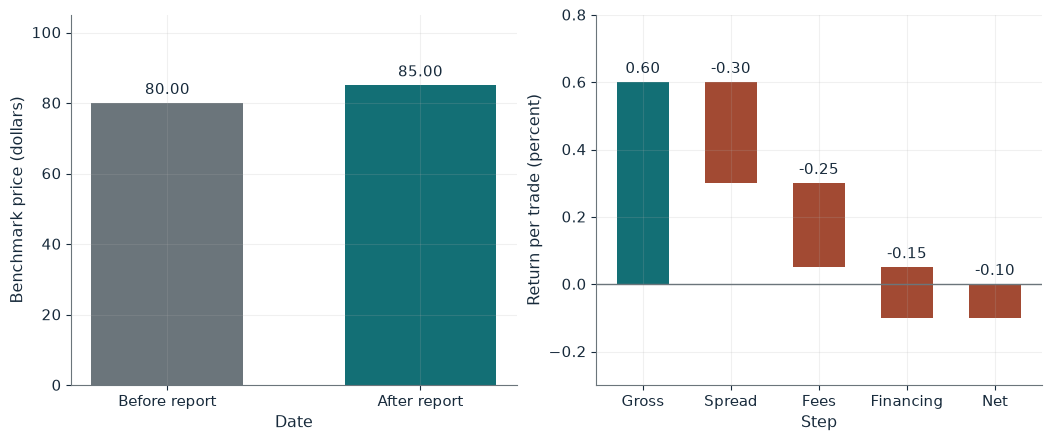

Price before report           $80.00
Benchmark price after report  $85.00
Expected return at new price  10.00%
Net abnormal return           -0.10%

Worked steps:
  1. Old price = 88/1.10 = 80.00
  2. New price = 93.50/1.10 = 85.00
  3. Return at new price = 93.50/85.00 - 1 = 10.00%
  4. Net = 0.60 - 0.30 - 0.25 - 0.15 = -0.10%

With an expected payoff of 93.50 the benchmark price is 93.50/1.10 = 85.00, so the price must rise by 5.00 dollars, from 80.00 to 85.00. A buyer at 85.00 expects 93.50/85.00 - 1 = 10.00%, the normal return. Net abnormal return is 0.60 - 0.30 - 0.25 - 0.15 = -0.10 percent, so the public-data rule falls short of the benchmark by 0.10 percent per trade.


In [2]:
show(news_picture(payoff=93.50, spread=0.30))

Change one input, `spread`, and hold the others at the book's values:

In [3]:
sweep(news_picture, 'spread', [0.1, 0.2, 0.3], {'payoff': 93.5}, ['Benchmark price after report', 'Net abnormal return'])

spread | Benchmark price after report | Net abnormal return
0.1 | $85.00 | 0.10%
0.2 | $85.00 | 0.00%
0.3 | $85.00 | -0.10%


The price moves from 80 to 85, after which a buyer earns only the 10 percent normal return. The rule loses 0.10 percent net at the book's costs and breaks even exactly at a 0.20 percent spread.

## 2. Noise-trader risk: the margin call

A claim worth a certain 100 trades at 118. A trader with 45 dollars of capital shorts it; after one year the price is 95 or 165 with equal probability.

$$118-165=-47\text{ dollars}.$$

$$0.5(23)+0.5(-47)=-12\text{ dollars}.$$

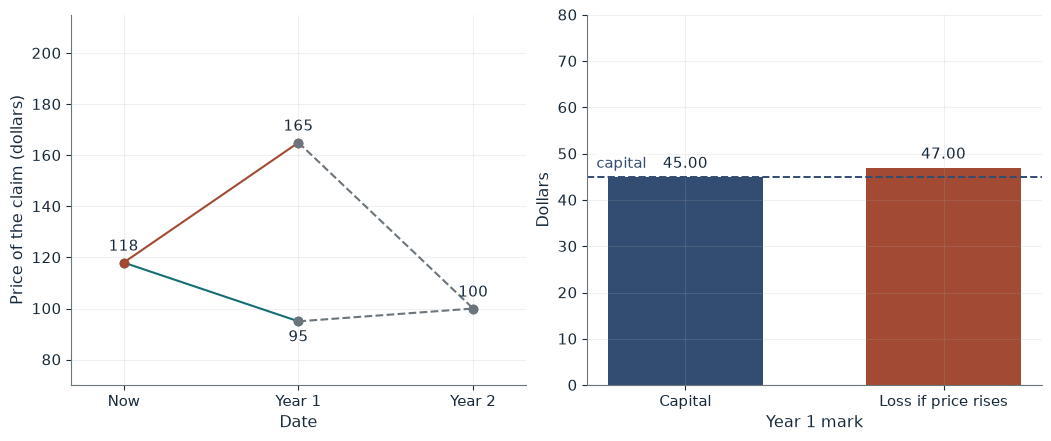

Marked P/L if price falls  $23.00
Marked P/L if price rises  -$47.00
Expected marked P/L        -$12.00
Forced close               yes
Profit at maturity         none (closed at 165)

Worked steps:
  1. Fall: 1.00(118 - 95) = 23.00
  2. Rise: 1.00(118 - 165) = -47.00
  3. Expected: 0.5(23.00) + 0.5(-47.00) = -12.00
  4. Loss 47.00 > capital 45: forced close

Short 1.00 claim at 118. If the price falls to 95 the mark is 1.00(118 - 95) = 23.00; if it rises to 165 the mark is 1.00(118 - 165) = -47.00. Expected marked P/L is 0.5(23.00) + 0.5(-47.00) = -12.00. The loss of 47.00 exceeds the 45 dollars of capital, so the broker closes the short at 165 and the later fall to 100 no longer helps.


In [4]:
show(noise_picture(size=1, high=165))

Change one input, `size`, and hold the others at the book's values:

In [5]:
sweep(noise_picture, 'size', [0.25, 0.5, 1], {'high': 165}, ['Marked P/L if price rises', 'Forced close', 'Profit at maturity'])

size | Marked P/L if price rises | Forced close | Profit at maturity
0.25 | -$11.75 | no | $4.50
0.5 | -$23.50 | no | $9.00
1 | -$47.00 | yes | none (closed at 165)


A full claim loses 47 at the mark, more than its 45 of capital, so it is closed at 165. Half a claim loses 23.50, survives, and earns 9 at maturity: smaller corrective demand.

## 3. Momentum effect: long winners, short losers

Legs of 400,000 dollars; winners return 8 percent and losers 2 percent, then in a reversal -4 and 10 percent.

$$MOM=8\%-2\%=6\%.$$

$$MOM=-4\%-10\%=-14\%.$$

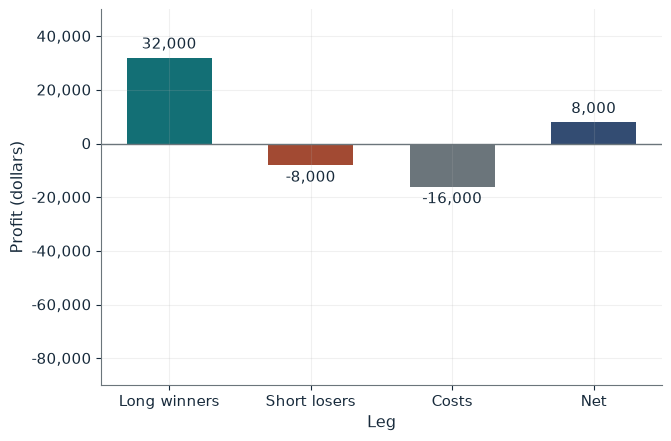

Long leg      $32,000
Short leg     -$8,000
Gross profit  $24,000
MOM           6%
Net return    2%

Worked steps:
  1. Long: 400,000 x 0.08 = 32,000
  2. Short: -400,000 x 0.02 = -8,000
  3. MOM = 8% - 2% = 6%
  4. Net = 6% - 4% = 2%

Long side: 400,000 x 0.08 = 32,000. Short side: -400,000 x 0.02 = -8,000. Gross 24,000, so MOM = 8% - 2% = 6%. After costs of 4% the net is 6% - 4% = 2%, a gain of $8,000 on one leg.


In [6]:
show(momentum_picture(regime='continuation', cost=0.04))

Change one input, `cost`, and hold the others at the book's values:

In [7]:
sweep(momentum_picture, 'cost', [0.0, 0.02, 0.04], {'regime': 'reversal'}, ['MOM', 'Net return'])

cost | MOM | Net return
0.0 | -14% | -14%
0.02 | -14% | -16%
0.04 | -14% | -18%


Continuation earns 32,000 - 8,000 = 24,000 gross, 6 percent, and 2 percent after 4 percent costs. The reversal loses 14 percent before costs and 18 percent after them.

## 4. Limits to arbitrage: redemptions force a sale

A fund with 1,000,000 of equity holds 10,000 units bought at 80 and 200,000 of cash. The price falls to 60 and clients redeem half of the remaining equity.

$$10{,}000(80-60)=200{,}000\text{ dollars},$$

$$\frac{200{,}000}{60} =3{,}333.33\text{ units}.$$

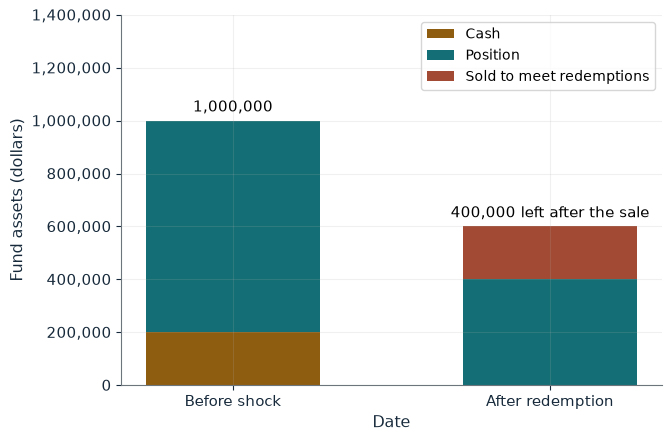

Position loss      $200,000
Equity after loss  $800,000
Redemption         $400,000
Units sold         3,333.33

Worked steps:
  1. Loss = 10,000(80 - 60) = 200,000
  2. Equity = 1,000,000 - 200,000 = 800,000
  3. Redemption = 0.50 x 800,000 = 400,000
  4. Units sold = max(0, 400,000 - 200,000)/60 = 3,333.33

The position loses 10,000(80 - 60) = 200,000, so equity falls to 800,000. Clients redeem 50% of it, 400,000. Cash covers 200,000, so the manager sells 200,000/60 = 3,333.33 units at the depressed price. The value estimate of 100 has not changed; the funding contract drives the sale.


In [8]:
show(redemption_picture(p=60, red=0.5))

Change one input, `p`, and hold the others at the book's values:

In [9]:
sweep(redemption_picture, 'p', [70, 60, 50], {'red': 0.5}, ['Equity after loss', 'Redemption', 'Units sold'])

p | Equity after loss | Redemption | Units sold
70 | $900,000 | $450,000 | 3,571.43
60 | $800,000 | $400,000 | 3,333.33
50 | $700,000 | $350,000 | 3,000.00


At 60 the fund sells 3,333.33 units into the discount it believes in. With a lockup (no redemptions) it sells nothing; a deeper drop to 50 shrinks equity and so cuts the sale to 3,000.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

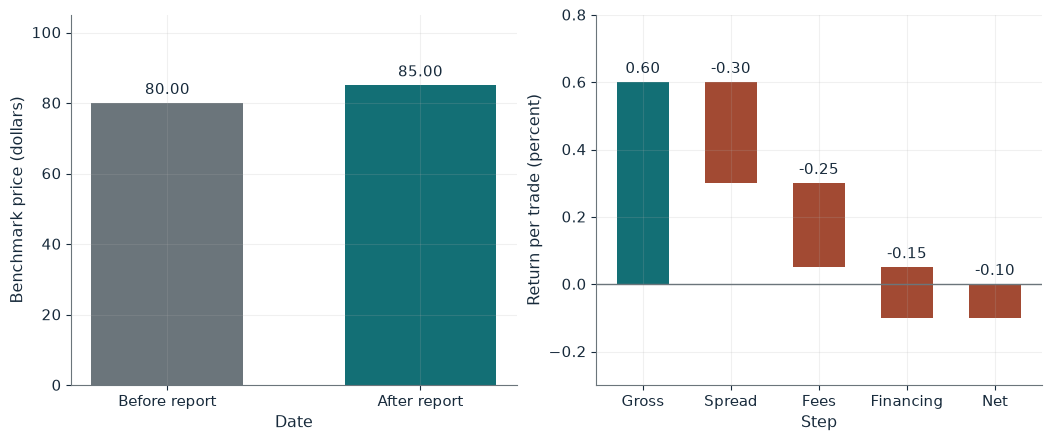

Price before report           $80.00
Benchmark price after report  $85.00
Expected return at new price  10.00%
Net abnormal return           -0.10%

Worked steps:
  1. Old price = 88/1.10 = 80.00
  2. New price = 93.50/1.10 = 85.00
  3. Return at new price = 93.50/85.00 - 1 = 10.00%
  4. Net = 0.60 - 0.30 - 0.25 - 0.15 = -0.10%

With an expected payoff of 93.50 the benchmark price is 93.50/1.10 = 85.00, so the price must rise by 5.00 dollars, from 80.00 to 85.00. A buyer at 85.00 expects 93.50/85.00 - 1 = 10.00%, the normal return. Net abnormal return is 0.60 - 0.30 - 0.25 - 0.15 = -0.10 percent, so the public-data rule falls short of the benchmark by 0.10 percent per trade.


In [10]:
show(news_picture(payoff=93.50, spread=0.30))

## Practice

**1.** The expected payoff rises to 99 with a 10 percent required return. What is the new benchmark price?

<details><summary>Answer</summary>

99/1.10 = 90 dollars; a buyer at 90 expects 99/90 - 1 = 10%.

</details>

**2.** Half a claim is short at 118 and the euphoric price is 190. What is the marked loss, and does it survive 45 of capital?

<details><summary>Answer</summary>

0.5(190 - 118) = 36, less than 45, so it survives and earns 0.5 x 18 = 9 at maturity.

</details>

**3.** Price 50, redemptions 50 percent: how many units must the fund sell?

<details><summary>Answer</summary>

Loss 10,000(80 - 50) = 300,000; equity 700,000; redemption 350,000; cash covers 200,000; sell 150,000/50 = 3,000 units.

</details>